In [ ]:
import pandas as pd
import numpy as np

# Creating a simulated messy dataset (predicting whether a student gets Placed: 1=Yes, 0=No)
data = {
    'Student_ID': [101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 101, 112],
    'CGPA': [8.5, 6.2, np.nan, 9.1, 7.4, 5.8, 8.9, 6.5, 7.8, np.nan, 8.5, 9.3],
    'Internships': ['2', '0', '1', '3', '1', '0', '2', '0', '1', '2', '2', '3'], # Stored as strings!
    'Department': ['CS', 'IT', 'CS', 'CS', 'ECE', 'ECE', 'IT', 'ECE', 'CS', 'IT', 'CS', 'CS'],
    'Placed': ['Yes', 'No', 'No', 'Yes', 'Yes', 'No', 'Yes', 'No', 'Yes', 'Yes', 'Yes', 'Yes']
}

df = pd.DataFrame(data)
print("Original Messy Data:\n", df)

Original Messy Data:
     Student_ID  CGPA Internships Department Placed
0          101   8.5           2         CS    Yes
1          102   6.2           0         IT     No
2          103   NaN           1         CS     No
3          104   9.1           3         CS    Yes
4          105   7.4           1        ECE    Yes
5          106   5.8           0        ECE     No
6          107   8.9           2         IT    Yes
7          108   6.5           0        ECE     No
8          109   7.8           1         CS    Yes
9          110   NaN           2         IT    Yes
10         101   8.5           2         CS    Yes
11         112   9.3           3         CS    Yes


Your Tasks (Complete these steps in Python)Remove Duplicates & Irrelevant Columns:Notice row 101 appears twice! Remove duplicate rows.Drop the Student_ID column because an ID number has no predictive pattern.Handle Missing Values (Nulls):Fill the missing (NaN) values in the CGPA column using the mean of CGPA.Fix Data Types:Notice Internships is stored as text strings ('2', '0'). Convert it to integers (int).Separate Features (X) and Target (y) & Encode Text:Set y to the Placed column and encode 'Yes'/'No' into 1/0 using LabelEncoder.Set X to the remaining columns and convert the categorical Department column into numerical dummy variables using pd.get_dummies(..., drop_first=True).Train & Evaluate Naïve Bayes:Split X and y using an 80-20 train-test split (random_state=42).   Train a GaussianNB() model.   Print the Confusion Matrix ($TP, TN, FP, FN$), Accuracy, Error Rate, Recall, Specificity, F1-Score, AUC, and 3-Fold Cross-Validation Accuracy (using cv=3 since this is a small practice dataset).   

In [ ]:
df = df.drop_duplicates()
df = df.drop(["Student_ID"], axis=1)
df["CGPA"] = df['CGPA'].fillna(df.CGPA.mean())


In [ ]:
df.Internshipts = df.Internships.astype("int")

/tmp/ipykernel_10500/1409527918.py:1: UserWarning: Pandas doesn't allow columns to be created via a new attribute name - see https://pandas.pydata.org/pandas-docs/stable/indexing.html#attribute-access
  df.Internshipts = df.Internships.astype("int")


In [ ]:
df = pd.get_dummies(df, drop_first=True)

In [ ]:
df

,CGPA,Internships_1,Internships_2,Internships_3,Department_ECE,Department_IT,Placed_Yes
0,8.500000,False,True,False,False,False,True
1,6.200000,False,False,False,False,True,False
2,7.722222,True,False,False,False,False,False
3,9.100000,False,False,True,False,False,True
4,7.400000,True,False,False,True,False,True
5,5.800000,False,False,False,True,False,False
6,8.900000,False,True,False,False,True,True
7,6.500000,False,False,False,True,False,False
8,7.800000,True,False,False,False,False,True
9,7.722222,False,True,False,False,True,True


In [ ]:
y = df["Placed_Yes"]
X = df.drop(["Placed_Yes"], axis=1)

y = y.replace({'Yes':1, 'No':0})
y = y.astype("int")

In [ ]:
from sklearn.model_selection import train_test_split, cross_val_score

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state=42)

In [ ]:
from sklearn.naive_bayes import GaussianNB

In [ ]:
nb = GaussianNB()
nb.fit(X_train, y_train)

GaussianNB()

In [ ]:
y_pred = nb.predict(X_test)

In [ ]:
c_score = cross_val_score(nb, X, y, cv=5)

/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)


In [ ]:
cm

array([[1, 0],
       [0, 2]])

## REgression

In [ ]:
import pandas as pd
import numpy as np

# Predicting Starting Salary Package (in LPA)
data = {
    'CGPA': [6.5, 7.0, 7.2, 7.5, 7.8, 8.0, 8.2, 8.5, 8.8, 9.0, 9.2, 9.5, 6.8, 7.4, 8.6],
    'Internships': [0, 1, 0, 1, 1, 2, 1, 2, 2, 3, 2, 3, 0, 1, 2],
    'Coding_Score': [55, 60, 58, 65, 70, 75, 72, 82, 85, 90, 88, 95, 52, 68, 84],
    'Package_LPA': [4.2, 5.1, 4.8, 6.0, 6.5, 7.8, 7.2, 9.0, 9.8, 11.2, 10.5, 12.5, 4.5, 6.2, 9.4]
}

df = pd.DataFrame(data)
print(df.head())

   CGPA  Internships  Coding_Score  Package_LPA
0   6.5            0            55          4.2
1   7.0            1            60          5.1
2   7.2            0            58          4.8
3   7.5            1            65          6.0
4   7.8            1            70          6.5


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split, cross_val_score

In [ ]:
X_single = df[['CGPA']]
y = df.Package_LPA


X_train, X_test, y_train, y_test = train_test_split(X_single, y, test_size=0.2, random_state=42)




In [ ]:
model = LinearRegression()

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

In [ ]:
r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)

In [ ]:
cv = cross_val_score(model, X_single, y, cv=3)

In [ ]:
print("r2:", r2)
print("mse:", mse)
print("cv:", cv)

r2: 0.927998982689433
mse: 0.9566535166664002
cv: [0.56419563 0.83469128 0.97754386]


In [ ]:
X_multi = df.iloc[:, :-1]
X_train, X_test, y_train, y_test = train_test_split(X_multi, y, test_size=0.2, random_state=42)

In [ ]:
model = LinearRegression()
model.fit(X_multi, y)
y_pred = model.predict(X_test)

In [ ]:
r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
cv = cross_val_score(model, X_single, y, cv=3)

print("r2:", r2)
print("mse:", mse)
print("cv:", cv)

r2: 0.9845051562568137
mse: 0.2058748238678023
cv: [0.56419563 0.83469128 0.97754386]


ridge and lasso

In [ ]:
import pandas as pd
import numpy as np

np.random.seed(42)

# Generating 30 student records
study_hours = np.random.uniform(1, 10, 30)
attendance = np.random.uniform(50, 100, 30)
shoe_size = np.random.uniform(6, 12, 30)         # Useless noise feature!
lucky_number = np.random.randint(1, 100, 30)     # Useless noise feature!

# True Exam Score depends ONLY on Study_Hours and Attendance (+ slight random noise)
exam_score = 5 * study_hours + 0.4 * attendance + np.random.normal(0, 2, 30)

df = pd.DataFrame({
    'Study_Hours': study_hours,
    'Attendance': attendance,
    'Shoe_Size': shoe_size,
    'Lucky_Number': lucky_number,
    'Exam_Score': exam_score
})

print(df.head())

   Study_Hours  Attendance  Shoe_Size  Lucky_Number  Exam_Score
0     4.370861   80.377243   8.332064            47   55.415165
1     9.556429   58.526206   7.628094            78   71.914473
2     7.587945   53.252580  10.972425             3   56.306823
3     6.387926   97.444277   8.140520             1   72.702601
4     2.404168   98.281602   7.685607             5   51.122965


In [ ]:
from sklearn.linear_model import Ridge, Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import mean_squared_error, r2_score

In [ ]:
#train_test slit
X = df.iloc[:, :-1]
y = df.Exam_Score

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state=42)



#scalling
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

X_scaled = scaler.transform(X)


#modeling
lasso_model = Lasso(alpha=1.0)
ridge_model = Ridge(alpha=1.0)

lasso_model.fit(X_train, y_train)
ridge_model.fit(X_train, y_train)

lasso_y_pred = lasso_model.predict(X_test)
ridge_y_pred = ridge_model.predict(X_test)


#evaluating
print(r2_score(y_test, lasso_y_pred))
print(mean_squared_error(y_test, lasso_y_pred))
print(cross_val_score(lasso_model, X_scaled, y, cv=5))



print(r2_score(y_test, ridge_y_pred))
print(mean_squared_error(y_test, ridge_y_pred))
print(cross_val_score(ridge_model, X_scaled, y, cv=5))


0.957891029778296
2.46776220872516
[0.93034219 0.98452238 0.94607347 0.95298368 0.95122001]
0.9390575675031204
3.5714820626524872
[0.94052064 0.99435342 0.95607858 0.95888889 0.96918603]


## Logistic Regression

In [ ]:
import pandas as pd
import numpy as np

data = {
    'Annual_Income': [3.5, 8.2, 4.0, 12.5, 2.8, 9.0, 5.5, 15.0, 3.2, 7.8, 6.0, 11.0, 4.5, 10.2, 3.0, 8.5],
    'Credit_Score': [580, 750, 610, 810, 520, 770, 660, 840, 550, 720, 680, 790, 630, 760, 540, 740],
    'Debt_Ratio': [0.65, 0.20, 0.55, 0.15, 0.80, 0.25, 0.45, 0.10, 0.70, 0.30, 0.40, 0.18, 0.50, 0.22, 0.75, 0.28],
    'Loan_Approved': [0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 0, 1]
}

df = pd.DataFrame(data)
print(df.head())

   Annual_Income  Credit_Score  Debt_Ratio  Loan_Approved
0            3.5           580        0.65              0
1            8.2           750        0.20              1
2            4.0           610        0.55              0
3           12.5           810        0.15              1
4            2.8           520        0.80              0


In [ ]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, recall_score


In [ ]:
#train test
X = df.iloc[:, :-1]
y = df.Loan_Approved

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

#standardization
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
X_scaled = scaler.transform(X)

#model
model = LogisticRegression(random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

#evaluation
cr = classification_report(y_test, y_pred)
cv = cross_val_score(model, X_scaled, y, cv=3)


In [ ]:
print(cr)

              precision    recall  f1-score   support

           0       1.00      1.00      1.00         2
           1       1.00      1.00      1.00         2

    accuracy                           1.00         4
   macro avg       1.00      1.00      1.00         4
weighted avg       1.00      1.00      1.00         4



KNN and DecisionTree

In [ ]:
import pandas as pd
from sklearn.datasets import load_breast_cancer

# Load built-in binary classification dataset (0 = Malignant, 1 = Benign)
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

print("Dataset Shape:", X.shape)
print(X.iloc[:, :4].head())  # Viewing first 4 columns

Dataset Shape: (569, 30)
   mean radius  mean texture  mean perimeter  mean area
0        17.99         10.38          122.80     1001.0
1        20.57         17.77          132.90     1326.0
2        19.69         21.25          130.00     1203.0
3        11.42         20.38           77.58      386.1
4        20.29         14.34          135.10     1297.0


In [ ]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, accuracy_score, precision_score, recall_score, roc_auc_score, f1_score

In [ ]:
#train_test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

#model
knn_model = KNeighborsClassifier(n_neighbors=3, metric="euclidean")
knn_model.fit(X_train, y_train)
knn_pred = knn_model.predict(X_test)
knn_prob = knn_model.predict_proba(X_test)[:,1]


dt_model = DecisionTreeClassifier(max_depth=4, criterion='gini')
dt_model.fit(X_train, y_train)
dt_pred = dt_model.predict(X_test)
dt_prob = dt_model.predict_proba(X_test)[:,1]


#metrics
def evaluate_model(name, y_true, y_pred, y_prob):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    acc = accuracy_score(y_true, y_pred)
    err = 1 - acc
    rec = recall_score(y_true, y_pred)
    spec = tn / (tn + fp)
    f1 = f1_score(y_true, y_pred)
    auc = roc_auc_score(y_true, y_prob)
    print(f"=== {name} ===")
    print(f"TP:{tp}, TN:{tn}, FP:{fp}, FN:{fn}")
    print(f"Accuracy:{acc:.4f} | Error:{err:.4f} | Recall:{rec:.4f} | Specificity:{spec:.4f} | F1:{f1:.4f} | AUC:{auc:.4f}\n")

evaluate_model("K-NN (K=5)", y_test, knn_pred, knn_prob)
evaluate_model("Decision Tree (Gini)", y_test, dt_pred, dt_prob)

=== K-NN (K=5) ===
TP:68, TN:40, FP:3, FN:3
Accuracy:0.9474 | Error:0.0526 | Recall:0.9577 | Specificity:0.9302 | F1:0.9577 | AUC:0.9764

=== Decision Tree (Gini) ===
TP:68, TN:40, FP:3, FN:3
Accuracy:0.9474 | Error:0.0526 | Recall:0.9577 | Specificity:0.9302 | F1:0.9577 | AUC:0.9363



SVM MLP


In [ ]:
from sklearn.datasets import make_moons
import pandas as pd

# Generate 200 points shaped like two interlocking crescent moons
X_raw, y = make_moons(n_samples=200, noise=0.2, random_state=42)
X = pd.DataFrame(X_raw, columns=['Feature_1', 'Feature_2'])

print(X.head())

   Feature_1  Feature_2
0  -1.106897   0.042293
1   0.956800   0.456750
2   0.733516   0.584617
3   1.111407  -0.309214
4   0.209082   0.000657


In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, recall_score, precision_score, roc_auc_score

In [ ]:
#train test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


#model
ann_model = MLPClassifier(hidden_layer_sizes=(64,32), max_iter=500)
ann_model.fit(X_train, y_train)
ann_y_pred = ann_model.predict(X_test)
ann_y_prob = ann_model.predict_proba(X_test)[:,1]

svm_model = SVC(kernel='rbf', C=1.0, probability=True, random_state=42)
svm_model.fit(X_trainm y_train)
ann_y_pred = ann_model.predict(X_test)
ann_y_prob = ann_model.predict_proba(X_test)[:,1]

#

KMeans

In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

data = {
    'Customer_ID': range(1, 21),
    'Annual_Income': [15, 16, 17, 18, 19, 45, 48, 50, 52, 55, 80, 82, 85, 88, 90, 20, 49, 86, 18, 53],
    'Spending_Score': [81, 85, 78, 88, 82, 48, 52, 45, 50, 47, 15, 18, 12, 20, 14, 79, 49, 16, 84, 51]
}

df = pd.DataFrame(data)
print(df.head())

   Customer_ID  Annual_Income  Spending_Score
0            1             15              81
1            2             16              85
2            3             17              78
3            4             18              88
4            5             19              82


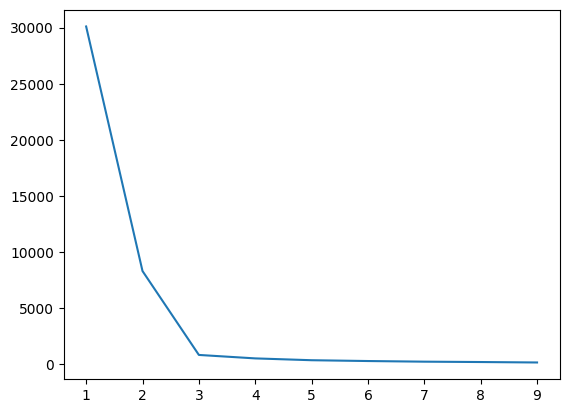

In [47]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score


wcss = []
for k in range(1,10):
  model = KMeans(n_clusters=k, n_init=10)
  model.fit(df)
  wcss.append(model.inertia_)
import matplotlib.pyplot as plt
plt.plot(range(1,10), wcss)
plt.show()


model = KMeans(n_clusters=3, n_init=10)
model_labels = model.fit_predict(df)

Inertia values (K=1 to 7): [600.0, 222.36, 139.82, 114.09, 90.93, 81.54, 72.63]
K-Means Silhouette Score: 0.4599
Hierarchical Silhouette Score: 0.4467


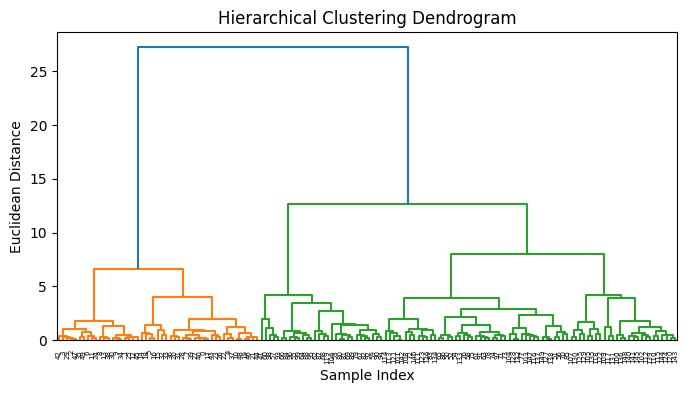

In [49]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage

# 1. Load & Scale X (Ignore y—clustering is unsupervised!)
data = load_iris()
X = data.data
X_scaled = StandardScaler().fit_transform(X)

# ==========================================
# MODEL 11: K-MEANS CLUSTERING[cite: 2]
# ==========================================
# Elbow Method to check optimal K
inertia = []
for k in range(1, 8):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertia.append(km.inertia_)
print("Inertia values (K=1 to 7):", [round(i, 2) for i in inertia])

# Fit final K-Means with K=3
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
km_labels = kmeans.fit_predict(X_scaled)
print("K-Means Silhouette Score:", round(silhouette_score(X_scaled, km_labels), 4))

# ==========================================
# MODEL 12: HIERARCHICAL CLUSTERING[cite: 2]
# ==========================================
hc = AgglomerativeClustering(n_clusters=3, metric='euclidean', linkage='ward')
hc_labels = hc.fit_predict(X_scaled)
print("Hierarchical Silhouette Score:", round(silhouette_score(X_scaled, hc_labels), 4))

# Plot Dendrogram (Using SciPy)
plt.figure(figsize=(8, 4))
dendrogram(linkage(X_scaled, method='ward'))
plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Sample Index")
plt.ylabel("Euclidean Distance")
plt.show()

Help on KMeans in module sklearn.cluster._kmeans object:

class KMeans(_BaseKMeans)
 |  KMeans(
 |      n_clusters=8,
 |      *,
 |      init='k-means++',
 |      n_init='auto',
 |      max_iter=300,
 |      tol=0.0001,
 |      verbose=0,
 |      random_state=None,
 |      copy_x=True,
 |      algorithm='lloyd'
 |  )
 |
 |  K-Means clustering.
 |
 |  Read more in the :ref:`User Guide <k_means>`.
 |
 |  Parameters
 |  ----------
 |
 |  n_clusters : int, default=8
 |      The number of clusters to form as well as the number of
 |      centroids to generate.
 |
 |      For an example of how to choose an optimal value for `n_clusters` refer to
 |      :ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.
 |
 |  init : {'k-means++', 'random'}, callable or array-like of shape             (n_clusters, n_features), default='k-means++'
 |      Method for initialization:
 |
 |      * 'k-means++' : selects initial cluster centroids using sampling             based on an empiri